<a href="https://colab.research.google.com/github/prafullp151/Project/blob/main/stockpred.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install pmdarima

import os
import warnings
warnings.filterwarnings('ignore')
from pylab import rcParams
rcParams['figure.figsize'] = 10, 6
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima_model import ARIMA
from pmdarima.arima import auto_arima
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
import numpy as np
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import yfinance as yf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 18.1 MB/s  0:00:00


In [3]:
stk = yf.Ticker("GS")
stkhist = stk.history(start="2000-01-01")
stkhist.tail()
splitidx = 0.9

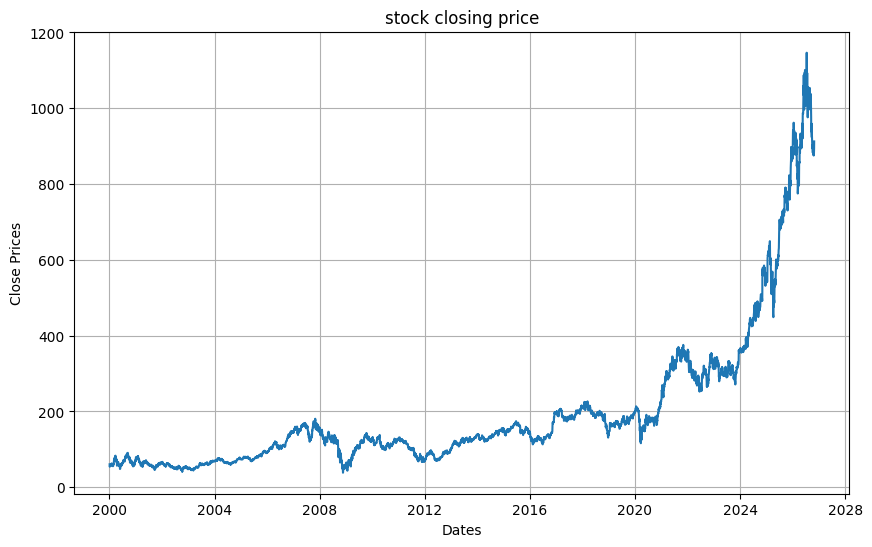

In [4]:
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Close Prices')
plt.plot(stkhist['Close'])
plt.title('stock closing price')
plt.show()

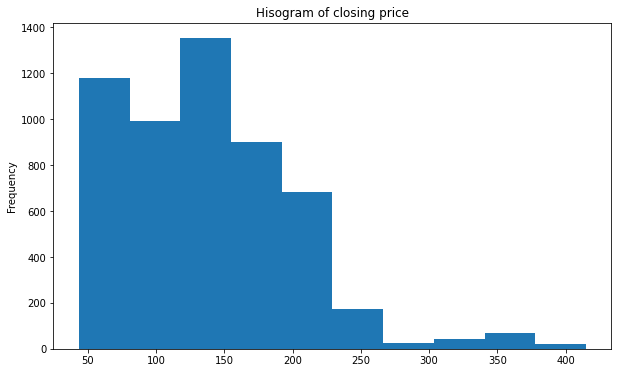

In [ ]:
plt.figure(figsize=(10,6))
df_close = stkhist['Close']
df_close.plot(style='k.',kind='hist')
plt.title('Hisogram of closing price')
plt.show()

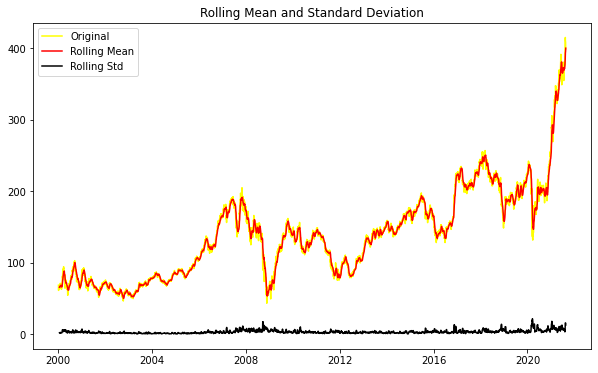

Results of dickey fuller test
Test Statistics                   0.773606
p-value                           0.991198
No. of lags used                  9.000000
Number of observations used    5432.000000
critical value (1%)              -3.431554
critical value (5%)              -2.862072
critical value (10%)             -2.567053
dtype: float64


In [ ]:
from statsmodels.tsa.stattools import adfuller
def test_stationarity(timeseries):
    #Determing rolling statistics
    rolmean = timeseries.rolling(12).mean()
    rolstd = timeseries.rolling(12).std()
    #Plot rolling statistics:
    plt.plot(timeseries, color='yellow',label='Original')
    plt.plot(rolmean, color='red', label='Rolling Mean')
    plt.plot(rolstd, color='black', label = 'Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean and Standard Deviation')
    plt.show(block=False)
    print("Results of dickey fuller test")
    adft = adfuller(timeseries,autolag='AIC')
    # output for dft will give us without defining what the values are.
    #hence we manually write what values does it explains using a for loop
    output = pd.Series(adft[0:4],index=['Test Statistics','p-value','No. of lags used','Number of observations used'])
    for key,values in adft[4].items():
        output['critical value (%s)'%key] =  values
    print(output)

test_stationarity(stkhist['Close'])

<Figure size 720x432 with 0 Axes>

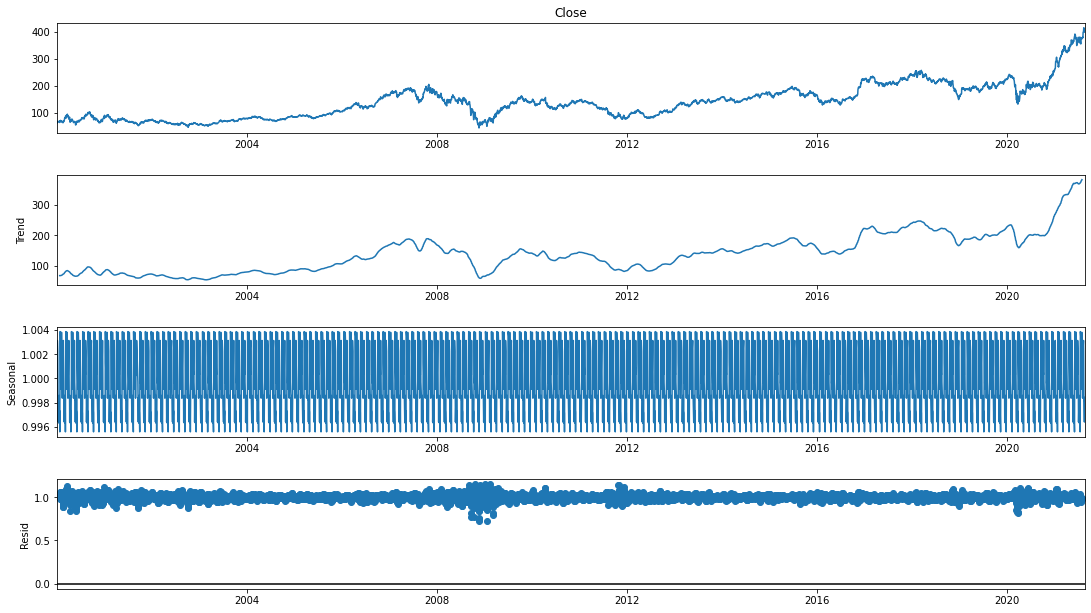

In [ ]:
result = seasonal_decompose(df_close, model='multiplicative', freq = 30)
fig = plt.figure()
fig = result.plot()
fig.set_size_inches(16, 9)

No handles with labels found to put in legend.


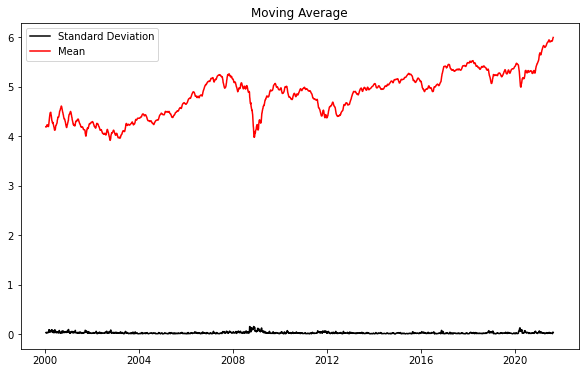

In [ ]:
from pylab import rcParams
rcParams['figure.figsize'] = 10, 6
df_log = np.log(stkhist['Close'])
moving_avg = df_log.rolling(12).mean()
std_dev = df_log.rolling(12).std()
plt.legend(loc='best')
plt.title('Moving Average')
plt.plot(std_dev, color ="black", label = "Standard Deviation")
plt.plot(moving_avg, color="red", label = "Mean")
plt.legend()
plt.show()

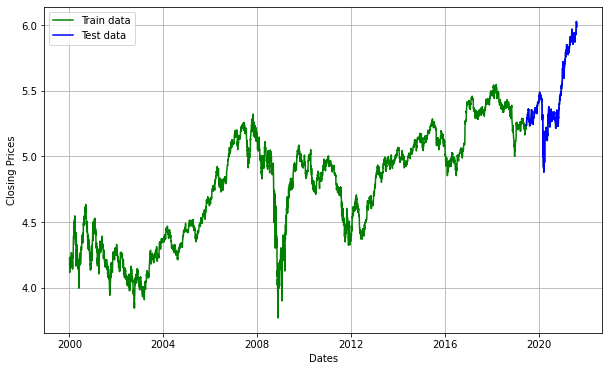

In [ ]:
train_data, test_data = df_log[3:int(len(df_log)*splitidx)], df_log[int(len(df_log)*splitidx):]
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(df_log, 'green', label='Train data')
plt.plot(test_data, 'blue', label='Test data')
plt.legend()

In [ ]:
model_autoARIMA = auto_arima(train_data, start_p=0, start_q=0,
test='adf',       # use adftest to find optimal 'd'
max_p=3, max_q=3, # maximum p and q
m=1,              # frequency of series
d=None,           # let model determine 'd'
seasonal=False,   # No Seasonality
start_P=0,
D=0,
trace=True,
error_action='ignore',
suppress_warnings=True,
stepwise=True)
print(model_autoARIMA.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-22982.592, Time=0.26 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-22989.490, Time=0.32 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-22990.077, Time=0.44 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-22984.148, Time=0.14 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-22994.361, Time=0.45 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-22990.605, Time=0.56 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-22994.583, Time=0.28 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-22993.048, Time=0.27 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-22986.456, Time=1.41 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=-22992.721, Time=1.48 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=-22990.952, Time=0.33 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=-22992.298, Time=1.17 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=-22995.978, Time=0.39 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=-22994.527, Time=0.27 sec
 ARIM

In [ ]:
model = ARIMA(train_data, order=model_autoARIMA.order)
#model = ARIMA(train_data, order=(1,1,2))
fitted = model.fit(disp=-1)
print(fitted.summary())

                             ARIMA Model Results                              
Dep. Variable:                D.Close   No. Observations:                 4893
Model:                 ARIMA(2, 1, 2)   Log Likelihood               11504.119
Method:                       css-mle   S.D. of innovations              0.023
Date:                Wed, 18 Aug 2021   AIC                         -22996.238
Time:                        20:14:02   BIC                         -22957.265
Sample:                             1   HQIC                        -22982.563
                                                                              
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0002      0.000      0.776      0.438      -0.000       0.001
ar.L1.D.Close    -0.2904      0.099     -2.921      0.003      -0.485      -0.095
ar.L2.D.Close     0.6331      0.095     

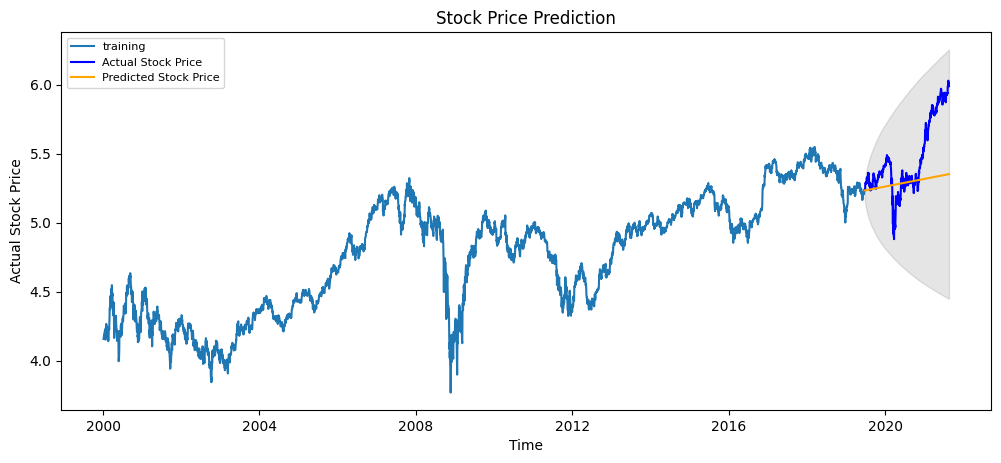

In [ ]:
# Forecast

fc, se, conf = fitted.forecast(len(test_data), alpha=0.05)  # 95% confidence
fc_series = pd.Series(fc, index=test_data.index)
lower_series = pd.Series(conf[:, 0], index=test_data.index)
upper_series = pd.Series(conf[:, 1], index=test_data.index)
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data, label='training')
plt.plot(test_data, color = 'blue', label='Actual Stock Price')
plt.plot(fc_series, color = 'orange',label='Predicted Stock Price')
plt.fill_between(lower_series.index, lower_series, upper_series,
                 color='k', alpha=.10)
plt.title('Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Actual Stock Price')
plt.legend(loc='upper left', fontsize=8)
plt.show()